In [8]:
# Project Description
# Using the AAPL (Apple Inc.) stock dataset, conduct the following analyses:

# Initial Data Exploration
# Load the dataset using Pandas. Check for null values and understand data types.
# Examine the time series properties of the data (e.g., frequency, trends).

import pandas as pd
file_path = "Apple Stock Prices (1981 to 2023).csv"
df = pd.read_csv(file_path) 
print(df.head())
print("Shape:", df.shape)
df.info()
print("\nNull values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["Date"].duplicated().sum())

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y"
)

df = (
    df.sort_values("Date")
)

print("Number of observations:", len(df))

print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

time_between_observations = df["Date"].diff()

most_common_frequency = time_between_observations.mode()[0]
print("Most common frequency:", most_common_frequency)

first_price = df["Adj Close"].iloc[0]
last_price = df["Adj Close"].iloc[-1]

print("\nFirst adjusted closing price:", first_price)
print("Last adjusted closing price:", last_price)

percentage_change = ((last_price - first_price) / first_price) * 100

print("Overall percentage change:", round(percentage_change, 2), "%")

         Date      Open      High       Low     Close  Adj Close    Volume
0  02/01/1981  0.154018  0.155134  0.154018  0.154018   0.119849  21660800
1  05/01/1981  0.151228  0.151228  0.150670  0.150670   0.117244  35728000
2  06/01/1981  0.144531  0.144531  0.143973  0.143973   0.112032  45158400
3  07/01/1981  0.138393  0.138393  0.137835  0.137835   0.107256  55686400
4  08/01/1981  0.135603  0.135603  0.135045  0.135045   0.105085  39827200
Shape: (10608, 7)
<class 'pandas.DataFrame'>
RangeIndex: 10608 entries, 0 to 10607
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10608 non-null  str    
 1   Open       10608 non-null  float64
 2   High       10608 non-null  float64
 3   Low        10608 non-null  float64
 4   Close      10608 non-null  float64
 5   Adj Close  10608 non-null  float64
 6   Volume     10608 non-null  int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 580.3 KB

Null values:
D

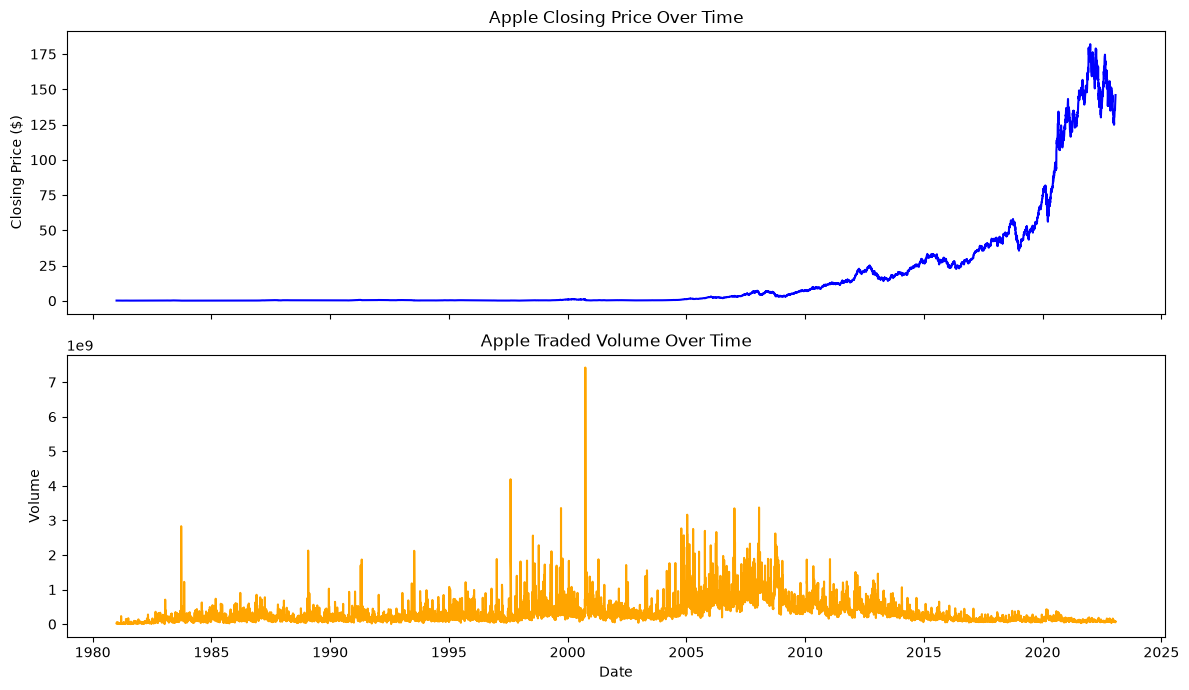

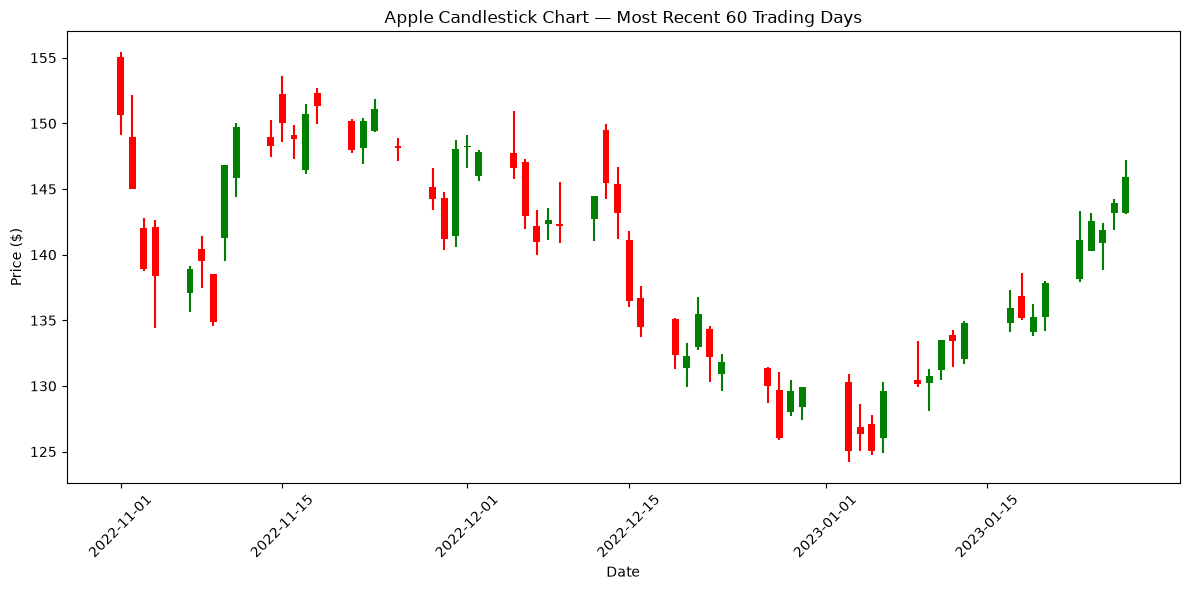

In [10]:
# Data Visualization
# Utilize Matplotlib to plot closing prices and traded volume over time.
# Create a candlestick chart to depict high and low prices.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(df["Date"], df["Close"], color="blue")
axes[0].set_title("Apple Closing Price Over Time")
axes[0].set_ylabel("Closing Price ($)")

axes[1].plot(df["Date"], df["Volume"], color="orange")
axes[1].set_title("Apple Traded Volume Over Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Volume")

plt.tight_layout()
plt.show()\

recent_data = df.tail(60)
colors = [
    "green" if close >= open_price else "red"
    for open_price, close in zip(
        recent_data["Open"],
        recent_data["Close"]
    )
]

plt.figure(figsize=(12, 6))

plt.vlines(
    recent_data["Date"],
    recent_data["Low"],
    recent_data["High"],
    color=colors
)

plt.bar(
    recent_data["Date"],
    recent_data["Close"] - recent_data["Open"],
    bottom=recent_data["Open"],
    color=colors,
    width=0.6
)

plt.title("Apple Candlestick Chart — Most Recent 60 Trading Days")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Statistical Analysis
# Compute summary statistics (mean, median, standard deviation) for key columns.
# Analyze closing prices with a moving average.

key_columns = ["Open", "High", "Low", "Close", "Volume"]
summary_statistics = df[key_columns].agg(
    ["mean", "median", "std"]
)

print(summary_statistics.round(2))
df["30-Day Moving Average"] = df["Close"].rolling(window=30).mean()

print(
    df[["Date", "Close", "30-Day Moving Average"]].tail(10)
)

         Open   High    Low  Close        Volume
mean    16.69  16.88  16.50  16.70  3.275098e+08
median   0.49   0.50   0.48   0.49  2.145976e+08
std     35.45  35.88  35.03  35.47  3.378203e+08
            Date       Close  30-Day Moving Average
10598 2023-01-13  134.759995             135.467333
10599 2023-01-17  135.940002             135.055000
10600 2023-01-18  135.210007             134.635000
10601 2023-01-19  135.270004             134.256333
10602 2023-01-20  137.869995             134.088333
10603 2023-01-23  141.110001             134.094000
10604 2023-01-24  142.529999             134.090000
10605 2023-01-25  141.860001             134.080000
10606 2023-01-26  143.960007             134.062333
10607 2023-01-27  145.929993             134.077666


In [12]:
# Hypothesis Testing
# Execute a t-test to compare average closing prices across different years.
# Examine daily returns’ distribution and test for normality using SciPy.

from scipy.stats import ttest_ind, normaltest

df["Year"] = df["Date"].dt.year

prices_2021 = df[df["Year"] == 2021]["Close"]
prices_2022 = df[df["Year"] == 2022]["Close"]

t_result = ttest_ind(prices_2021, prices_2022)

print("T-test p-value:", t_result.pvalue)

daily_returns = df["Close"].pct_change().dropna()

print("\nDaily returns summary:")
print(daily_returns.describe())

normality_result = normaltest(daily_returns)

print("\nNormality test p-value:", normality_result.pvalue)

T-test p-value: 4.481243580809856e-26

Daily returns summary:
count    10607.000000
mean         0.001052
std          0.028235
min         -0.518692
25%         -0.013109
50%          0.000000
75%          0.014684
max          0.332280
Name: Close, dtype: float64

Normality test p-value: 0.0
